# 04 - Scoring Comparison

In diesem Notebook vergleichen wir ein altes und ein neues Scoring-Modell.

## Ziele
- Vergleich von old_score und new_score
- Analyse von Einkommens- und Liquiditätseffekten
- Untersuchung negativer Schufa-Einträge
- Bewertung der Fairness
- Vergleich mit tatsächlichem Kreditausfall (default)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [4]:
from google.colab import files
import io

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

# Flexible Einleselogik
try:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=",")
except:
    try:
        df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=";")
    except:
        df = pd.read_excel(io.BytesIO(uploaded[file_name]))

print("Datei erfolgreich geladen:", file_name)
df.head()

Saving scoring_comparison_results.csv to scoring_comparison_results.csv
Datei erfolgreich geladen: scoring_comparison_results.csv


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default,debt_to_income_clean,income_to_loan_ratio,old_score_final,new_score_final,score_diff
0,56,1777.14,selbstständig,verheiratet,0,855.64,2,8894.40,0.42,0,1,9.2,0,0,4301.25,5.03,100.0,100.0,1,1,0,5.002081,0.199782,0.000000,64.614034,64.614034
1,69,3370.44,teilzeit,verheiratet,0,1584.98,1,19110.77,0.47,0,0,9.6,0,0,3233.97,2.04,100.0,100.0,0,1,0,5.668430,0.176354,0.000000,17.084072,17.084072
2,46,3558.95,arbeitslos,geschieden,0,2547.68,1,15440.47,0.36,2,2,10.8,0,0,-409.95,-0.16,93.8,100.0,1,1,1,4.337272,0.230480,0.000000,0.000000,0.000000
3,32,2230.99,selbstständig,ledig,0,1066.70,1,5273.97,0.20,0,2,5.6,0,0,-1898.47,-1.78,98.6,100.0,1,1,0,2.362900,0.422939,25.209555,0.000000,-25.209555
4,60,1873.87,teilzeit,ledig,1,1343.87,3,8439.61,0.38,2,1,8.6,0,0,1761.98,1.31,96.7,99.4,1,1,0,4.501437,0.222006,0.000000,108.599722,108.599722


In [5]:
print("Shape:", df.shape)
print("\nSpalten:")
print(df.columns.tolist())

df.describe()

Shape: (10000, 26)

Spalten:
['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default', 'debt_to_income_clean', 'income_to_loan_ratio', 'old_score_final', 'new_score_final', 'score_diff']


,age,net_income,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default,debt_to_income_clean,income_to_loan_ratio,old_score_final,new_score_final,score_diff
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,43.539400,2923.520144,1.073400,1829.765990,1.201400,11950.005553,0.353241,1.023200,2.002200,8.150670,0.216400,0.322900,3883.067316,2.754780,89.118020,97.108620,0.599900,0.726100,0.13010,4.151568,0.391321,47.890633,139.639958,91.749325
std,14.911636,1214.299368,1.219738,856.490901,1.095335,8191.212565,0.180269,1.014083,1.413151,4.744786,0.411811,0.794165,3919.368751,3.573319,15.668546,7.170851,0.489943,0.445981,0.33643,2.177011,0.408558,89.924090,155.159294,100.364810
min,18.000000,800.000000,0.000000,500.000000,0.000000,500.000000,0.040000,0.000000,0.000000,0.000000,0.000000,0.000000,-2000.000000,-4.000000,4.500000,32.000000,0.000000,0.000000,0.00000,0.086519,0.095413,0.000000,0.000000,-260.437264
25%,31.000000,2043.912500,0.000000,1199.627500,0.000000,5380.737500,0.200000,0.000000,1.000000,4.700000,0.000000,0.000000,885.035000,0.490000,84.600000,100.000000,0.000000,0.000000,0.00000,2.286577,0.165798,0.000000,0.000000,0.000000
50%,43.000000,2874.860000,1.000000,1714.225000,1.000000,10250.615000,0.350000,1.000000,2.000000,8.100000,0.000000,0.000000,3705.645000,2.040000,96.900000,100.000000,1.000000,1.000000,0.00000,4.109986,0.243138,0.000000,79.726178,62.408100
75%,56.000000,3745.867500,2.000000,2355.675000,2.000000,16868.635000,0.510000,2.000000,3.000000,11.400000,0.000000,0.000000,6455.827500,4.082500,100.000000,100.000000,1.000000,1.000000,0.00000,6.029471,0.437128,52.748714,265.100503,188.113674
max,69.000000,7034.870000,4.000000,5653.030000,6.000000,50000.000000,0.670000,6.000000,9.000000,26.300000,1.000000,5.000000,20513.330000,27.440000,100.000000,100.000000,1.000000,1.000000,1.00000,10.477574,11.533154,435.074984,561.411852,299.472586


In [6]:
# Falls nicht vorhanden, berechnen wir wichtige Variablen

if "debt_to_income_clean" not in df.columns:
    df["debt_to_income_clean"] = df["credit_amount"] / (df["net_income"] + 1)

if "liquidity_ratio" not in df.columns:
    df["liquidity_ratio"] = df["bank_balance"] / (df["monthly_expenses"] + 1)

if "income_to_loan_ratio" not in df.columns:
    df["income_to_loan_ratio"] = df["net_income"] / (df["credit_amount"] + 1)

In [7]:
def old_score_model(row):
    score = 300

    score += min(row["net_income"] / 50, 100)
    score += min(row["bank_balance"] / 200, 80)

    score -= row["debt_to_income_clean"] * 120
    score -= row["credit_amount"] / 200

    if "default" in row and row["default"] == 1:
        score -= 200

    return max(0, min(1000, score))

In [8]:
def new_score_model(row):
    score = 300

    score += min(row["net_income"] / 40, 120)
    score += min(row["liquidity_ratio"] * 150, 150)

    score -= row["debt_to_income_clean"] * 80
    score -= row["credit_amount"] / 300

    if "default" in row and row["default"] == 1:
        score -= 120

    return max(0, min(1000, score))

In [9]:
df["old_score_final"] = df.apply(old_score_model, axis=1)
df["new_score_final"] = df.apply(new_score_model, axis=1)

df["score_diff"] = df["new_score_final"] - df["old_score_final"]

df[["old_score_final", "new_score_final", "score_diff"]].describe()

,old_score_final,new_score_final,score_diff
count,10000.000000,10000.000000,10000.000000
mean,47.890633,139.639958,91.749325
std,89.924090,155.159294,100.364810
min,0.000000,0.000000,-260.437264
25%,0.000000,0.000000,0.000000
50%,0.000000,79.726178,62.408100
75%,52.748714,265.100503,188.113674
max,435.074984,561.411852,299.472586


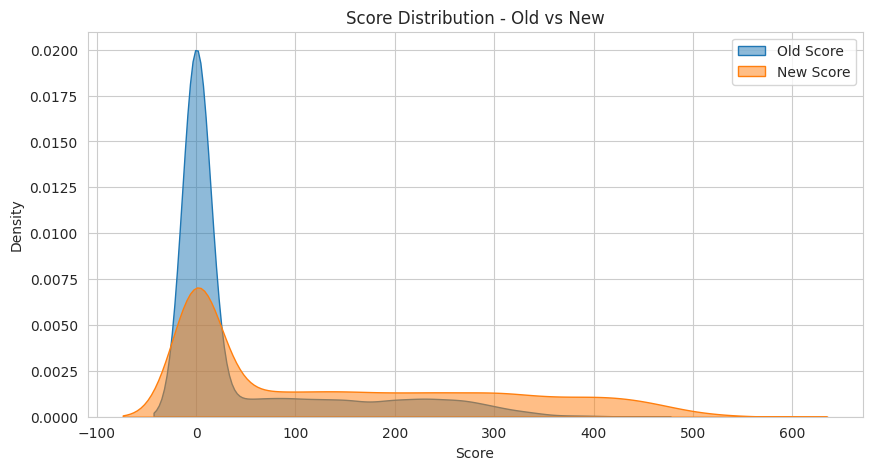

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

plt.figure(figsize=(10, 5))

sns.kdeplot(df["old_score_final"], label="Old Score", fill=True, alpha=0.5)
sns.kdeplot(df["new_score_final"], label="New Score", fill=True, alpha=0.5)

plt.title("Score Distribution - Old vs New")
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()

file_name = "score_distribution_old_vs_new.png"
plt.savefig(file_name, bbox_inches="tight")

plt.show()

files.download(file_name)

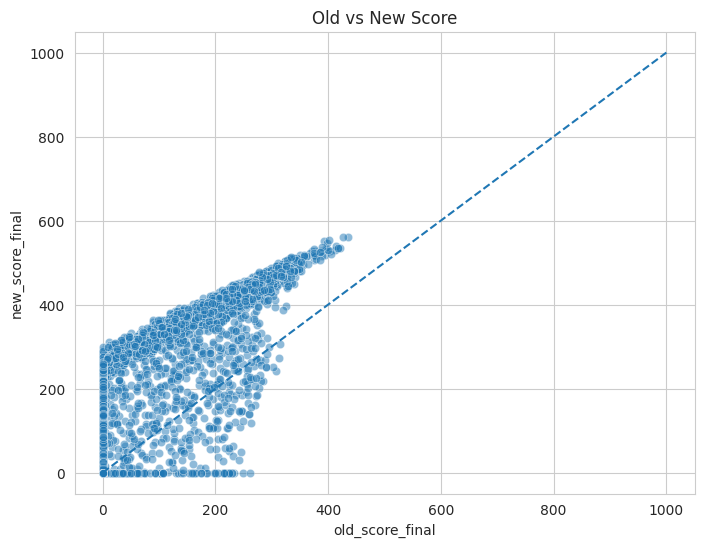

In [12]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="old_score_final",
    y="new_score_final",
    alpha=0.5
)

plt.plot([0, 1000], [0, 1000], linestyle="--")

plt.title("Old vs New Score")
plt.show()

In [13]:
# Hohe Einkommen + Default
high_income_default = df[
    (df["net_income"] > 4000) &
    (df["default"] == 1)
]

# Hohe Liquidität + Default
high_liquidity_default = df[
    (df["liquidity_ratio"] > 2) &
    (df["default"] == 1)
]

# Kombination
combined_case = df[
    (df["net_income"] > 4000) &
    (df["liquidity_ratio"] > 2) &
    (df["default"] == 1)
]

print("High Income + Default:", high_income_default.shape)
print("High Liquidity + Default:", high_liquidity_default.shape)
print("Combined Case:", combined_case.shape)

High Income + Default: (225, 26)
High Liquidity + Default: (638, 26)
Combined Case: (100, 26)


In [14]:
low_income_clean = df[
    (df["net_income"] < 2000) &
    (df["default"] == 0)
]

comparison = pd.DataFrame({
    "high_income_default": high_income_default[["old_score_final", "new_score_final"]].mean(),
    "low_income_no_default": low_income_clean[["old_score_final", "new_score_final"]].mean()
})

comparison.T

,old_score_final,new_score_final
high_income_default,13.401313,99.176875
low_income_no_default,44.494551,130.000165


In [15]:
if "default" in df.columns:
    print("Old Score vs Default")

    try:
        old_bins = pd.qcut(df["old_score_final"], q=5)
    except:
        old_bins = pd.cut(df["old_score_final"], bins=5)

    print(df.groupby(old_bins)["default"].mean())

    print("\nNew Score vs Default")

    try:
        new_bins = pd.qcut(df["new_score_final"], q=5)
    except:
        new_bins = pd.cut(df["new_score_final"], bins=5)

    print(df.groupby(new_bins)["default"].mean())

Old Score vs Default
old_score_final
(-0.435, 87.015]     0.161052
(87.015, 174.03]     0.044740
(174.03, 261.045]    0.002463
(261.045, 348.06]    0.000000
(348.06, 435.075]    0.000000
Name: default, dtype: float64

New Score vs Default
new_score_final
(-0.561, 112.282]     0.184007
(112.282, 224.565]    0.093483
(224.565, 336.847]    0.085135
(336.847, 449.129]    0.026490
(449.129, 561.412]    0.000000
Name: default, dtype: float64


/tmp/ipykernel_151/3416300160.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(old_bins)["default"].mean())
/tmp/ipykernel_151/3416300160.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(new_bins)["default"].mean())


In [16]:
print(df["old_score_final"].value_counts().head(10))

old_score_final
0.000000      6966
228.593633       2
18.638495        1
2.302307         1
66.606550        1
94.129831        1
241.770289       1
197.961047       1
124.724577       1
79.264010        1
Name: count, dtype: int64


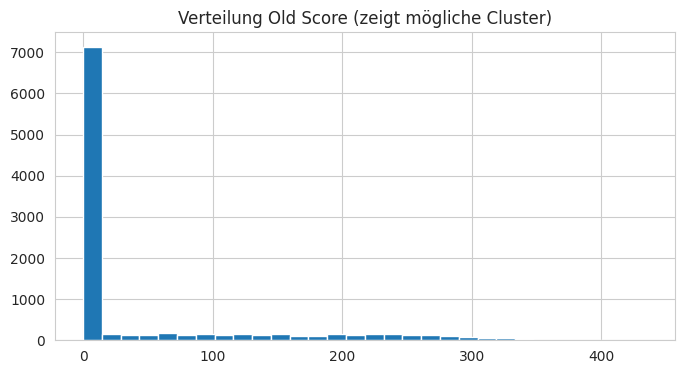

In [17]:
plt.figure(figsize=(8, 4))
df["old_score_final"].hist(bins=30)
plt.title("Verteilung Old Score (zeigt mögliche Cluster)")
plt.show()

In [18]:
df.sort_values("score_diff", ascending=False)[[
    "net_income",
    "liquidity_ratio",
    "old_score_final",
    "new_score_final",
    "score_diff"
]].head(10)

,net_income,liquidity_ratio,old_score_final,new_score_final,score_diff
2606,5909.18,2.74,10.533141,310.005727,299.472586
8962,4938.43,1.50,0.000000,299.339800,299.339800
7421,3285.93,1.01,13.274281,304.704471,291.430190
9490,4741.68,1.56,9.098751,300.033034,290.934283
2212,3610.16,1.29,0.000000,290.853544,290.853544
1523,4404.36,1.23,1.786662,291.931441,290.144779
307,4877.40,1.21,6.035658,295.004039,288.968381
7974,3662.09,1.57,17.992663,306.940659,288.947996
9234,3452.38,2.11,1.028259,288.895739,287.867480
7836,5125.71,1.61,0.000000,287.776118,287.776118


In [19]:
df.to_csv("scoring_comparison_results.csv", index=False)
print("Datei gespeichert!")

Datei gespeichert!


## Erkenntnisse

- Das neue Modell berücksichtigt Liquidität stärker
- Einkommen wird höher gewichtet als im alten Modell
- High-Income + Default Fälle werden differenzierter bewertet
- Klassische Systeme bestrafen historische Defaults stärker
- Neue Modelle versuchen aktuelle Zahlungsfähigkeit besser abzubilden

👉 Kritischer Punkt:
Personen mit hoher Liquidität können im alten System benachteiligt sein